<a href="https://colab.research.google.com/github/VaidyaVaibhava/AVVI-AI-image-Generator/blob/main/AVVI_Image_Generator.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
!pip install -q diffusers transformers accelerate sentencepiece huggingface_hub

In [4]:
import torch

from diffusers import AutoPipelineForText2Image
from huggingface_hub import login
from google.colab import userdata

[transformers] `Siglip2ImageProcessorFast` is deprecated. The `Fast` suffix for image processors has been removed; use `Siglip2ImageProcessor` instead.


In [5]:
hf_token = userdata.get("HF_TOKEN")
login(token=hf_token)

In [6]:
pipeline = AutoPipelineForText2Image.from_pretrained("stabilityai/sdxl-turbo", torch_dtype=torch.float16, variant="fp16")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


model_index.json:   0%|          | 0.00/685 [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 18 files:   0%|          | 0/18 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/517 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

In [7]:
pipeline = pipeline.to("cuda")

In [8]:
prompt = "A cinematic shot of a majestic dinosaur perched on top of a mountain peak, highly detailed, 8k resolution"


In [9]:
image = pipeline(prompt=prompt, num_inference_steps=4, guidance_scale=0.0).images[0]

  0%|          | 0/4 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/diffusers/pipelines/stable_diffusion_xl/pipeline_stable_diffusion_xl.py:748: FutureWarning: `upcast_vae` is deprecated and will be removed in version 1.0.0. `upcast_vae` is deprecated. Please use `pipe.vae.to(torch.float32)`. For more details, please refer to: https://github.com/huggingface/diffusers/pull/12619#issue-3606633695.
  deprecate(
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


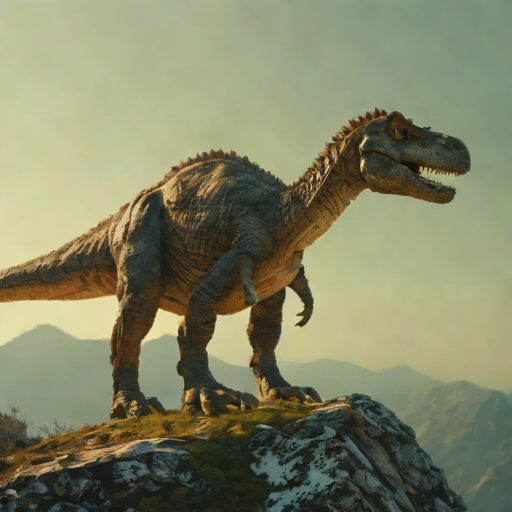

In [10]:
image

In [11]:
image.save("Generated_image.png")

In [12]:
!pip install gradio

In [13]:
import gradio as gr

In [14]:
def generate_image(prompt):
  image = pipeline(prompt=prompt, num_inference_steps=4, guidance_scale=0.0).images[0]
  return image

In [1]:
import gradio as gr

app = gr.Interface(
    fn=generate_image,
    inputs=gr.Textbox(label="Enter prompt", placeholder="Describe the image you want to generate"),
    outputs=gr.Image(label="Generated Image"),
    title="AI Image Generator",
    description="Generate images using AI"
)

app.launch(share=True)

NameError: name 'generate_image' is not defined